<a href="https://colab.research.google.com/github/dairxp/Py-Colab-ALD/blob/main/02_Deep_Learning_Construyendo_una_Red_Neuronal.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

df = pd.read_csv('/content/drive/MyDrive/Machine Learning/Data/train.csv').head(1000)

In [ ]:
df.head()

,label,pixel0,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,...,pixel774,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783
0,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [ ]:
Y = df.label.values
X = df.drop("label", axis=1)

In [ ]:
print('Data seleccionado tiene {} filas y {} columnas'.format(X.shape[0], X.shape[1]))
X.head()

Data seleccionado tiene 1000 filas y 784 columnas


,pixel0,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel774,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


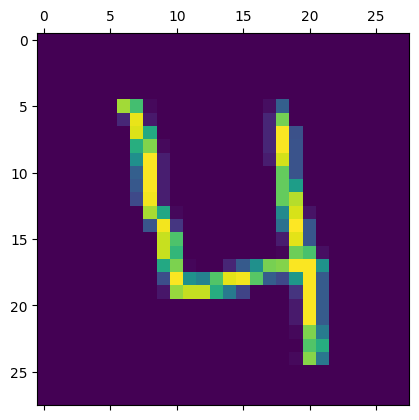

In [ ]:
i = 3
plt.matshow(X.to_numpy()[i].reshape(28, 28))
plt.show()

##**RED NEURONAL**
Vamos a representar los numeros de forma vectorial

|num|->|0,1,2,3,4,5,6,7,8,9|
|:---|:---|:--------------|
|0|->|1,0,0,0,0,0,0,0,0,0|
|1|->|0,1,0,0,0,0,0,0,0,0|
|2|->|0,0,1,0,0,0,0,0,0,0|
|3|->|0,0,0,1,0,0,0,0,0,0|
|4|->|0,0,0,0,1,0,0,0,0,0|
|5|->|0,0,0,0,0,1,0,0,0,0|
|6|->|0,0,0,0,0,0,1,0,0,0|
|7|->|0,0,0,0,0,0,0,1,0,0|
|8|->|0,0,0,0,0,0,0,0,1,0|
|9|->|0,0,0,0,0,0,0,0,0,1|


In [ ]:
def One_hot(j):
  e = np.zeros(10)
  e[j] = 1.0
  return e

# aplicamos la funcion creada
y_n = np.array([One_hot(number) for number in Y])

# contrastamos el nuevo vector en comparación al númer original
for a, b in zip(y_n[:15], Y[:15]):
  print(b, '-->', a)

1 --> [0. 1. 0. 0. 0. 0. 0. 0. 0. 0.]
0 --> [1. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
1 --> [0. 1. 0. 0. 0. 0. 0. 0. 0. 0.]
4 --> [0. 0. 0. 0. 1. 0. 0. 0. 0. 0.]
0 --> [1. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
0 --> [1. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
7 --> [0. 0. 0. 0. 0. 0. 0. 1. 0. 0.]
3 --> [0. 0. 0. 1. 0. 0. 0. 0. 0. 0.]
5 --> [0. 0. 0. 0. 0. 1. 0. 0. 0. 0.]
3 --> [0. 0. 0. 1. 0. 0. 0. 0. 0. 0.]
8 --> [0. 0. 0. 0. 0. 0. 0. 0. 1. 0.]
9 --> [0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]
1 --> [0. 1. 0. 0. 0. 0. 0. 0. 0. 0.]
3 --> [0. 0. 0. 1. 0. 0. 0. 0. 0. 0.]
3 --> [0. 0. 0. 1. 0. 0. 0. 0. 0. 0.]


Normalizamos la entrada, **NOTA: Es muy importante**

In [ ]:
X = X/255     # puede ser X/max(X) para otras aplicaciones

In [ ]:
lr = 0.01
w0 = np.random.randn(X.shape[1], 16)
w1 = np.random.randn(16, 16)
w2 = np.random.randn(16, 10)    # es 10 porque son 10 salidas de la red neuronal

# inicializamos los bias
b0 = np.random.randn(1, 16)
b1 = np.random.randn(1, 16)
b2 = np.random.randn(1, 10)

# feedforward --> Donde a0, a1, a2, a3 serán los valores de la funcion de activación
z0, z1, z2, a0, a1, a2, a3 = [], [], [], [], [], [], []

y = Y
mse = 0
output = np.zeros(y.shape)
errors = []

In [ ]:
def sigmoid(t):
  return 1/(1+np.exp(-t))

def Derivada_sigmoid(p):
  return sigmoid(p) * sigmoid(1-p)

##Asignación de los pesos y variables con ls función **FeedForward**

In [ ]:
def feedforward(x_input):
  global a0, z0, a1, z1, a2, z2, a3
  a0 = x_input
  z0 = np.dot(a0, w0) + b0    # np.dot retorna el producto punto de dos arreglos
  a1 = sigmoid(z0)
  z1 = np.dot(a1, w1) + b1
  a2 = sigmoid(z1)
  z2 = np.dot(a2, w2) + b2
  a3 = sigmoid(z2)            # Capa de salida

  output = a3
  return output

##Función **Backdrop** y generación de **NN**

In [ ]:
def backprop():
  # aplicamos la regla de la cadena para la función de perdida respecto a los pesos 2, 1
  # .T es la matriz Transpuesta
  global mse, w0, w1, w2, b0, b1, b2
  mse = np.sum((y_n - output)**2)
  errors.append(mse)

  delta2 = -(y_n - output) * Derivada_sigmoid(z2)   # no esta al inicio el '2*' por razones de computo
  d_w2 = np.dot(a2.T, delta2)     # transponemos la activación
  d_b2 = delta2     # cambio del bias en la capa 3

  delta1 = np.dot(delta2, w2.T) * Derivada_sigmoid(z1)
  d_w1 = np.dot(a1.T, delta1)
  d_b1 = delta1

  delta0 = np.dot(delta1, w1.T) * Derivada_sigmoid(z0)
  d_w0 = np.dot(a0.T, delta0)
  d_b0 = delta0

  # actualizamos los pesos respectivos
  w2 = w2 - lr * d_w2
  w1 = w1 - lr * d_w1
  w0 = w0 - lr * d_w0

  # Trabajamos y actualizamos los valores de los bias
  b2 = b2 - lr * d_b2.mean(axis=0).reshape(b2.shape)
  b1 = b1 - lr * d_b1.mean(axis=0).reshape(b1.shape)
  b0 = b0 - lr * d_b0.mean(axis=0).reshape(b0.shape)


In [ ]:
for i in range(10000):
  output = feedforward(X)
  backprop()
  if i%100 == 0:
    print('Epoch ={}, mse={}'.format(i, mse))

Epoch =0, mse=3337.8096499443336
Epoch =100, mse=498.09807246437015
Epoch =200, mse=308.66996466714534
Epoch =300, mse=245.98088955156553
Epoch =400, mse=171.0357961835802
Epoch =500, mse=111.50719754361066
Epoch =600, mse=65.1693480116779
Epoch =700, mse=50.110179167968965
Epoch =800, mse=43.359619982158364
Epoch =900, mse=39.24488294917715
Epoch =1000, mse=36.25042043263844
Epoch =1100, mse=33.70267289122448
Epoch =1200, mse=31.887598182577797
Epoch =1300, mse=30.065845574277354
Epoch =1400, mse=28.732878266108287
Epoch =1500, mse=28.003706496120046
Epoch =1600, mse=27.437665661398828
Epoch =1700, mse=26.401078361044394
Epoch =1800, mse=25.92983890572457
Epoch =1900, mse=25.52645836892854
Epoch =2000, mse=24.855220721271603
Epoch =2100, mse=24.38150641710409
Epoch =2200, mse=24.00151317387466
Epoch =2300, mse=23.50797893587839
Epoch =2400, mse=21.82511136908353
Epoch =2500, mse=21.481806353967052
Epoch =2600, mse=21.242810054481357
Epoch =2700, mse=21.065444530810517
Epoch =2800, mse

In [ ]:
# veamos la ultima salida
output

array([[6.11432544e-05, 9.86254453e-01, 3.91368452e-05, ...,
        8.97757927e-05, 8.72538320e-06, 5.25947519e-04],
       [9.96081106e-01, 4.40065311e-07, 1.59489551e-03, ...,
        5.22443524e-04, 4.65999256e-04, 3.49718701e-07],
       [7.82947328e-05, 9.99319602e-01, 1.58027015e-05, ...,
        4.69038795e-05, 1.28270819e-05, 1.02842659e-03],
       ...,
       [2.04456117e-05, 8.31098400e-03, 1.48367691e-07, ...,
        1.11898519e-02, 1.21901352e-05, 9.97657306e-01],
       [1.96754981e-03, 7.86024554e-03, 2.99979291e-03, ...,
        1.78574640e-03, 4.01484648e-05, 1.41958839e-08],
       [6.21402811e-05, 1.06160954e-07, 1.28051244e-04, ...,
        7.16062686e-04, 3.12546848e-03, 7.42400942e-04]])

##Visualización e Interpretación

In [ ]:
# Seleccionamos el valor mas alto
y_hat = output.argmax(axis=1)
y_hat[:15]

array([], dtype=int64)

In [ ]:
# Contrastamos la salida con los datos iniciales
y[:15]

array([1, 0, 1, 4, 0, 0, 7, 3, 5, 3, 8, 9, 1, 3, 3])

In [ ]:
# [1, 0, 1, 4, 0, 0, 7, 3, 5, 3, 8, 9, 1, 3, 3]
# [1, 0, 1, 4, 0, 0, 7, 3, 5, 3, 8, 9, 1, 3, 3]

In [ ]:
# Mostramos las predicciones diferentes o las que se equivoco
# True: significa los lugares donde la red neuronal se equivoco
y != y_hat

array([False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False,  True, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False,  True, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False,

In [ ]:
# Contamos la cantidad de equivocaciones
print((y != y_hat).sum())

17


In [ ]:
# Mostramos los registros y sus indices donde el modelo se equivocó
errores = X[y != y_hat].index
X[y != y_hat]

,pixel0,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel774,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783
40,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
67,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
131,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
173,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
251,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
284,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
397,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
457,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
499,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
546,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


El numero escrito es 9
El numero predicho es 5


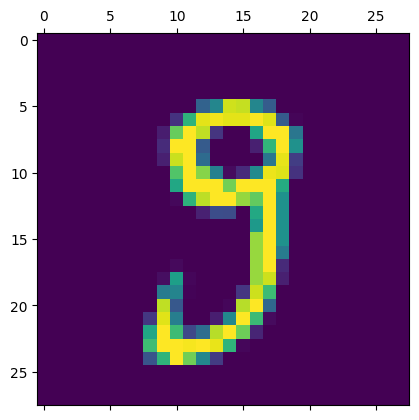

El numero escrito es 8
El numero predicho es 3


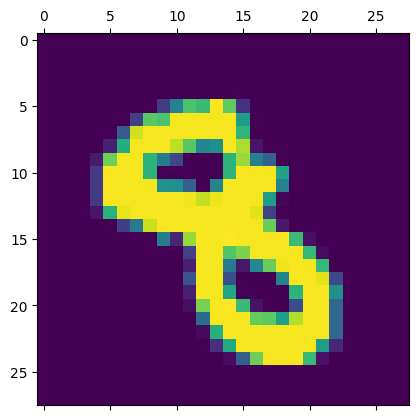

El numero escrito es 8
El numero predicho es 6


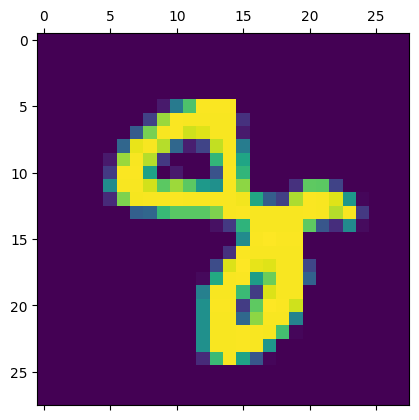

El numero escrito es 7
El numero predicho es 4


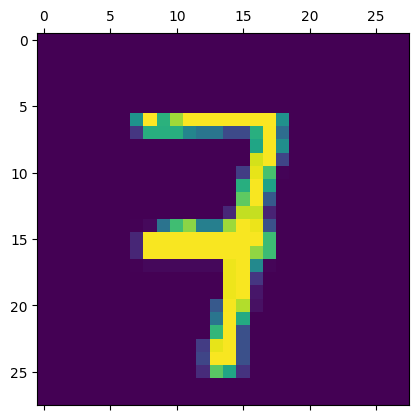

El numero escrito es 0
El numero predicho es 6


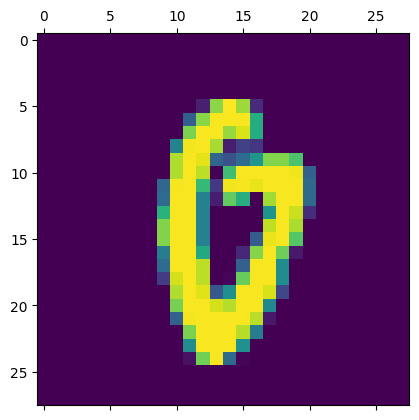

El numero escrito es 3
El numero predicho es 1


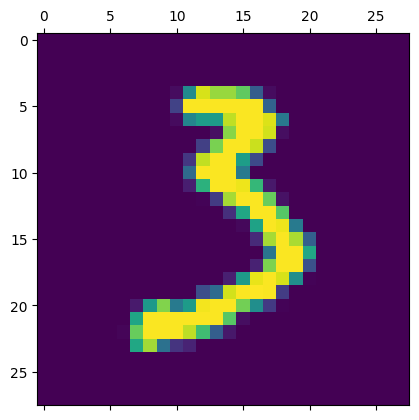

El numero escrito es 2
El numero predicho es 8


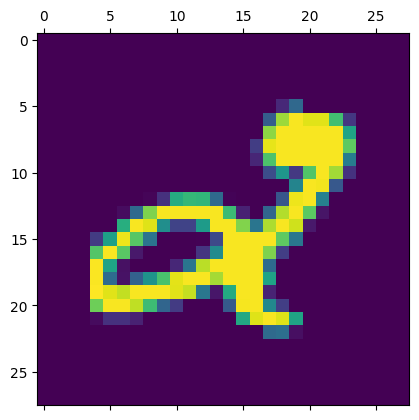

El numero escrito es 9
El numero predicho es 2


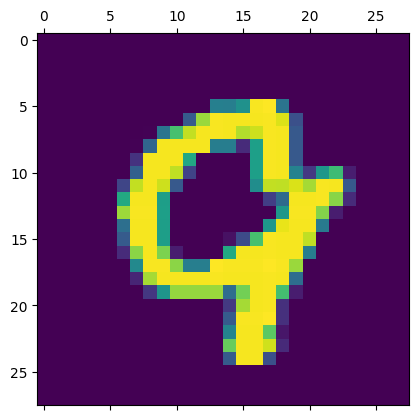

El numero escrito es 9
El numero predicho es 0


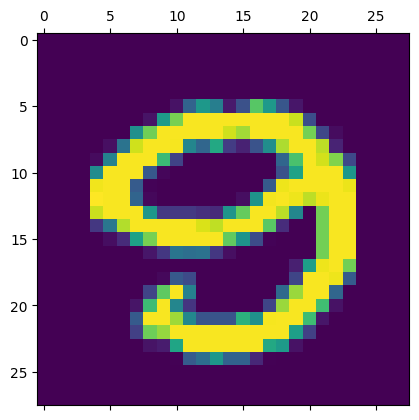

El numero escrito es 9
El numero predicho es 7


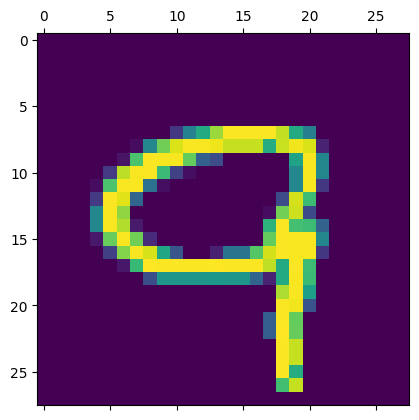

El numero escrito es 7
El numero predicho es 2


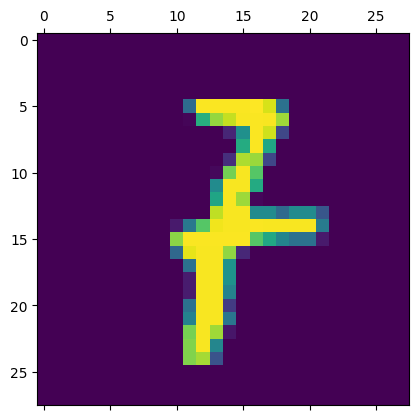

El numero escrito es 2
El numero predicho es 8


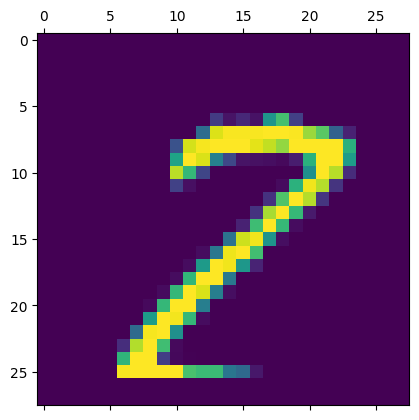

El numero escrito es 3
El numero predicho es 7


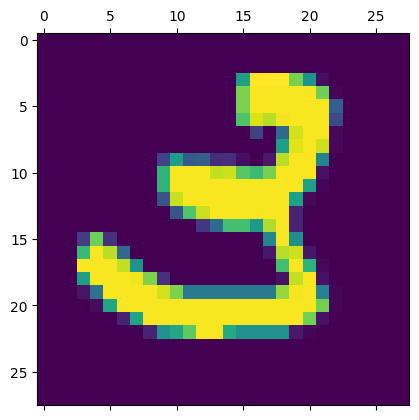

El numero escrito es 9
El numero predicho es 0


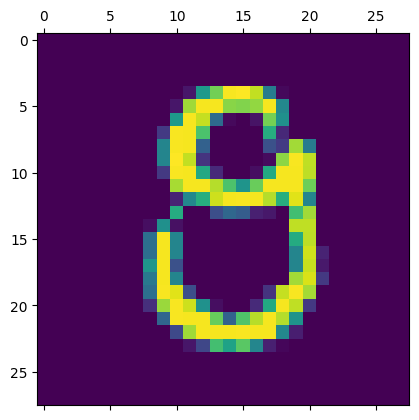

El numero escrito es 7
El numero predicho es 2


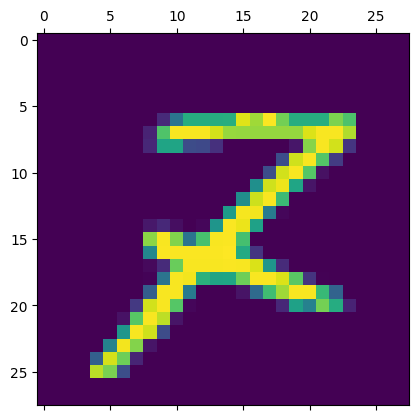

El numero escrito es 1
El numero predicho es 7


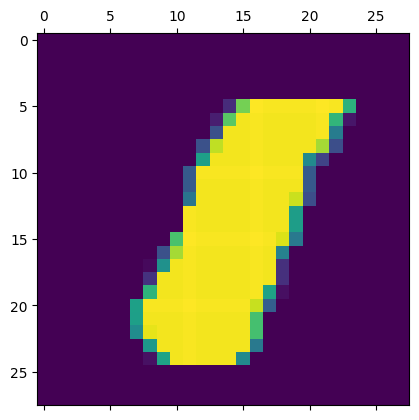

El numero escrito es 2
El numero predicho es 0


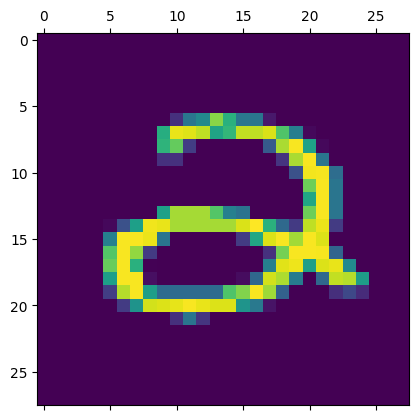

In [ ]:
# Mostramos graficamente los errores encontrados
for i in errores:
  plt.matshow(X.iloc[i].values.reshape(28,28))
  print('El numero escrito es {}'.format(y[i]))
  print('El numero predicho es {}'.format(y_hat[i]))
  plt.show()